# Задача 4.17
# Углы случайного остроугольного треугольника в кубе

## Условие
В кубе объёма 1 независимо равномерно выбираются точки A, B, C. T — треугольник остроугольный; R — наименьший угол меньше $26.7^\circ$; S — наибольший угол меньше $81.9^\circ$. Получить **100000 остроугольных треугольников** и оценить $P(R\mid T)$ и $P(S\mid T)$.

## Теория с нуля и решение вручную
### 1. Выбор точек и отбор по условию
Можно взять единичный куб $[0,1]^3$: перенос и поворот куба не меняют расстояния и углы. Все девять координат трёх точек независимы и равномерны на $[0,1]$. Вырожденный треугольник имеет вероятность ноль. Мы генерируем тройки, проверяем T и сохраняем только остроугольные, пока их не станет ровно 100000. Это метод отбраковки. Принятые независимые тройки имеют распределение исходной тройки при условии T.

### 2. Стороны и углы вручную
В пространстве расстояние $AB=\sqrt{(x_A-x_B)^2+(y_A-y_B)^2+(z_A-z_B)^2}$. Вычислим три квадрата сторон и упорядочим их $s_1\le s_2\le s_3$. Они противоположны соответственно наименьшему, среднему и наибольшему углам. По теореме косинусов:
$$\cos\alpha_{\min}=\frac{s_2+s_3-s_1}{2\sqrt{s_2s_3}},\qquad\cos\alpha_{\max}=\frac{s_1+s_2-s_3}{2\sqrt{s_1s_2}}.$$
Треугольник остроугольный тогда и только тогда, когда $s_3<s_1+s_2$. Угол получаем через $\arccos$, который возвращает радианы; перевод в градусы: $\alpha_{\circ}=180\alpha_{\text{рад}}/\pi$. Функция косинуса убывает на $[0,\pi]$, поэтому при сравнении через косинусы знак неравенства обращается; в коде для понятности вычисляем сами углы.

### 3. Условные частоты
После отбора знаменатель уже равен числу принятых остроугольных треугольников:
$$\widehat P(R\mid T)=\frac{\#\{\alpha_{\min}<26.7^\circ\}}{100000},\qquad \widehat P(S\mid T)=\frac{\#\{\alpha_{\max}<81.9^\circ\}}{100000}.$$
Число всех сгенерированных треугольников будет больше 100000 и не служит знаменателем этих двух оценок. Если взять только 100000 произвольных троек, остроугольных окажется меньше — это не выполнит численное требование условия.

### 4. Пример ручной проверки
Пусть точки $(0,0,0)$, $(1,0,0)$, $(1/2,\sqrt3/2,0)$. Все стороны равны 1, все углы $60^\circ$. Значит T происходит, R не происходит, S происходит. Если стороны имеют квадраты 1,1,2, то самый большой угол $90^\circ$, T не происходит: равенство нужно исключить.

### 5. Переход к коду
Генерируем пакетами, чтобы не хранить лишние точки. `np.sum(...,axis=1)` складывает три квадрата разностей координат каждой пары. Оставляем только строки с T, берём недостающее число строк и продолжаем. `np.clip(cos,-1,1)` устраняет исключительно возможную погрешность вычислений перед `arccos`: настоящий косинус не выходит за этот интервал. На графиках ось — число **принятых** опытов, что прямо указано в названиях. Ответы в листке около 0.11 и 0.65 — ориентиры; выводим исходную частоту и оба формата округления.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Сгенерировано троек: 240000 ; принято: 100000
R при условии T; N — число принятых остроугольных треугольников: успехов 11321, знаменатель 100000
  частота = 0.11321000; ориентир 95%: [0.11124615; 0.11517385]


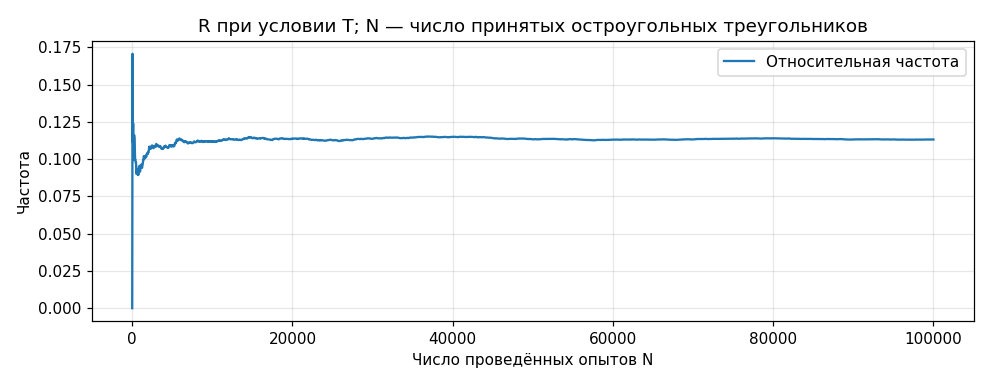

S при условии T; N — число принятых остроугольных треугольников: успехов 65316, знаменатель 100000
  частота = 0.65316000; ориентир 95%: [0.65020994; 0.65611006]


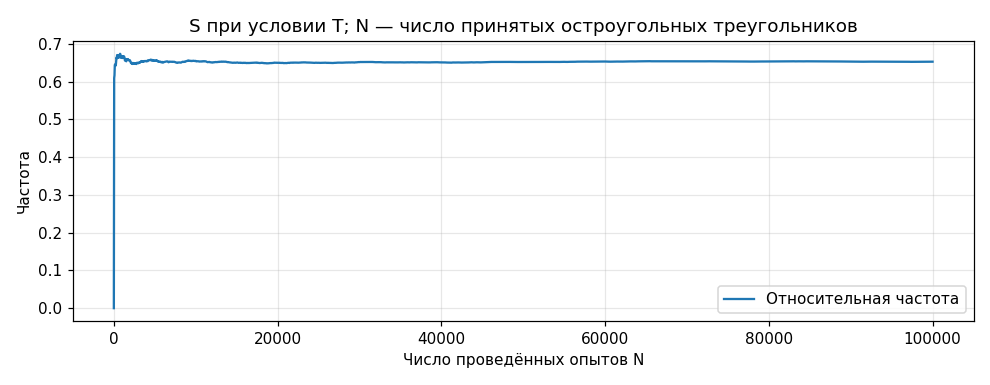

P(R|T): два знака 0.11; один знак 0.1
P(S|T): два знака 0.65; один знак 0.7


In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

target = 100_000
accepted = []
count = 0
generated = 0
while count < target:
    batch = 30_000
    A = rng.random((batch,3))
    B = rng.random((batch,3))
    C = rng.random((batch,3))
    AB2 = np.sum((A-B)**2, axis=1)
    AC2 = np.sum((A-C)**2, axis=1)
    BC2 = np.sum((B-C)**2, axis=1)
    sides2 = np.sort(np.column_stack((AB2,AC2,BC2)), axis=1)
    T = sides2[:,2] < sides2[:,0]+sides2[:,1]
    good = sides2[T]
    # Оставляем ровно столько, сколько ещё нужно до 100000.
    take = min(len(good), target-count)
    accepted.append(good[:take])
    count += take
    generated += batch
sides2 = np.vstack(accepted)
s1,s2,s3 = sides2[:,0],sides2[:,1],sides2[:,2]
cos_min = (s2+s3-s1)/(2*np.sqrt(s2*s3))
cos_max = (s1+s2-s3)/(2*np.sqrt(s1*s2))
angle_min = np.degrees(np.arccos(np.clip(cos_min,-1,1)))
angle_max = np.degrees(np.arccos(np.clip(cos_max,-1,1)))
R = angle_min < 26.7
S = angle_max < 81.9
print('Сгенерировано троек:', generated, '; принято:', len(sides2))
pR = report(R, 'R при условии T; N — число принятых остроугольных треугольников')
pS = report(S, 'S при условии T; N — число принятых остроугольных треугольников')
for name,value in [('P(R|T)',pR),('P(S|T)',pS)]:
    print(f'{name}: два знака {value:.2f}; один знак {value:.1f}')
